# KrishiDrishti: Price Model (Model B)

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, RandomizedSearchCV, GroupKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, make_scorer
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

from src.history import HistoryAdjustedRegressor
from src.predict import predict_prices, recommend_crops

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

## Data

### Monthly mandi prices (median modal price per district, crop and month)

In [2]:
df = pd.read_csv("data/processed/price_monthly.csv")
df.head()

,district,crop,commodity,year,month,modal_price_median,records,markets
0,Agra,Arhar/Tur,Arhar (Tur/Red Gram)(Whole),2002,11,1575.0,3,1
1,Agra,Arhar/Tur,Arhar (Tur/Red Gram)(Whole),2002,12,1462.5,2,1
2,Agra,Arhar/Tur,Arhar (Tur/Red Gram)(Whole),2003,1,1472.5,22,1
3,Agra,Arhar/Tur,Arhar (Tur/Red Gram)(Whole),2003,2,1760.0,21,1
4,Agra,Arhar/Tur,Arhar (Tur/Red Gram)(Whole),2003,3,1700.0,21,1


In [3]:
df.shape

(114803, 8)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114803 entries, 0 to 114802
Data columns (total 8 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   district            114803 non-null  str    
 1   crop                114803 non-null  str    
 2   commodity           114803 non-null  str    
 3   year                114803 non-null  int64  
 4   month               114803 non-null  int64  
 5   modal_price_median  114803 non-null  float64
 6   records             114803 non-null  int64  
 7   markets             114803 non-null  int64  
dtypes: float64(1), int64(4), str(3)
memory usage: 10.2 MB


In [5]:
pd.DataFrame({"rows": df.groupby("crop").size(), "price_records": df.groupby("crop")["records"].sum(),
              "districts": df.groupby("crop")["district"].nunique(),
              "first_year": df.groupby("crop")["year"].min(), "last_year": df.groupby("crop")["year"].max()})

,rows,price_records,districts,first_year,last_year
crop,,,,,
Arhar/Tur,5248,112064,68,2002,2026
Bajra,3599,110485,59,2002,2026
Barley,6927,162364,63,2002,2026
Gram,11529,349004,73,2002,2026
Jowar,686,8846,44,2002,2026
Maize,6608,193639,65,2002,2026
Masoor,5336,131025,64,2002,2026
Moong(Green Gram),3761,62121,67,2002,2026
Peas & beans (Pulses),4485,100509,65,2006,2026


## Data Cleaning

### Duplicates and nulls

In [6]:
print("Duplicated district-crop-month rows:", df.duplicated(["district", "crop", "year", "month"]).sum())
print("Nulls:", df.isna().sum().sum())

Duplicated district-crop-month rows: 0
Nulls: 0


### Tidy crop names

In [7]:
df["crop"] = df["crop"].str.replace(r"\s*&\s*", " & ", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()
sorted(df["crop"].unique())

['Arhar/Tur',
 'Bajra',
 'Barley',
 'Gram',
 'Jowar',
 'Maize',
 'Masoor',
 'Moong(Green Gram)',
 'Peas & beans (Pulses)',
 'Potato',
 'Rapeseed & Mustard',
 'Rice',
 'Sesamum',
 'Urad',
 'Wheat']

### Drop months with fewer than 3 price records

In [8]:
before = len(df)
df = df[df["records"] >= 3]
print(f"Dropped {before - len(df):,} rows -> {len(df):,}")

Dropped 6,381 rows -> 108,422


### Drop prices far from the state price of the same crop and month (outside one third to three times)

In [9]:
df["value"] = df["modal_price_median"] * df["records"]
state_month = df.groupby(["crop", "year", "month"])[["value", "records"]].transform("sum")
ratio = df["modal_price_median"] / (state_month["value"] / state_month["records"])
far = (ratio > 3) | (ratio < 1 / 3)
display(df[far].groupby("crop").size().rename("rows").to_frame().T)
df = df[~far].reset_index(drop=True)
print(f"Dropped {far.sum()} rows -> {len(df):,}")

crop,Maize,Masoor,Moong(Green Gram),Peas & beans (Pulses),Potato,Rice,Wheat
rows,9,4,1,5,4,1,1


Dropped 25 rows -> 108,397


## Harvest Price (Target) and Pre-sowing Price

### Season, harvest months and pre-sowing months of each crop

In [10]:
crop_seasons = pd.DataFrame(
    [(crop, season) for crop, seasons in {
        "Rice": ["Kharif"], "Maize": ["Kharif", "Rabi"], "Bajra": ["Kharif"], "Jowar": ["Kharif"], "Arhar/Tur": ["Kharif"],
        "Urad": ["Kharif", "Summer"], "Moong(Green Gram)": ["Kharif", "Summer"], "Sesamum": ["Kharif"],
        "Wheat": ["Rabi"], "Barley": ["Rabi"], "Gram": ["Rabi"], "Masoor": ["Rabi"], "Peas & beans (Pulses)": ["Rabi"],
        "Rapeseed & Mustard": ["Rabi"], "Potato": ["Rabi"]}.items() for season in seasons],
    columns=["crop", "season"])

HARVEST_MONTHS = {"Kharif": [(0, 10), (0, 11), (0, 12)], "Rabi": [(1, 3), (1, 4), (1, 5)], "Summer": [(1, 6), (1, 7), (1, 8)]}
PRESOWING_MONTHS = {"Kharif": [(0, 3), (0, 4), (0, 5)], "Rabi": [(0, 8), (0, 9), (0, 10)], "Summer": [(0, 12), (1, 1), (1, 2)]}

month_name = lambda offset, month: pd.Timestamp(2000, month, 1).strftime("%b") + (" next year" if offset else "")
pd.DataFrame({"pre_sowing_months": {s: ", ".join(month_name(*m) for m in v) for s, v in PRESOWING_MONTHS.items()},
              "harvest_months": {s: ", ".join(month_name(*m) for m in v) for s, v in HARVEST_MONTHS.items()},
              "crops": crop_seasons.groupby("season")["crop"].apply(", ".join)})

,pre_sowing_months,harvest_months,crops
Kharif,"Mar, Apr, May","Oct, Nov, Dec","Rice, Maize, Bajra, Jowar, Arhar/Tur, Urad, Mo..."
Rabi,"Aug, Sep, Oct","Mar next year, Apr next year, May next year","Maize, Wheat, Barley, Gram, Masoor, Peas & bea..."
Summer,"Dec, Jan next year, Feb next year","Jun next year, Jul next year, Aug next year","Urad, Moong(Green Gram)"


### Average price of a window, weighted by the number of price records

In [11]:
def window_price(windows, name):
    parts = []
    for season, months in windows.items():
        for year_offset, month in months:
            part = df[df["month"] == month].assign(season=season)
            part["crop_year_start"] = part["year"] - year_offset
            parts.append(part)
    w = pd.concat(parts).merge(crop_seasons, on=["crop", "season"])
    by_district = w.groupby(["district", "crop", "season", "crop_year_start"])[["value", "records"]].sum()
    by_state = w.groupby(["crop", "season", "crop_year_start"]).agg(value=("value", "sum"), records=("records", "sum"),
                                                                    districts=("district", "nunique"))
    district_table = pd.DataFrame({name: by_district["value"] / by_district["records"], name + "_records": by_district["records"]}).reset_index()
    state_table = pd.DataFrame({"state_" + name: by_state["value"] / by_state["records"], "districts": by_state["districts"]}).reset_index()
    return district_table, state_table

harvest, state_harvest = window_price(HARVEST_MONTHS, "harvest_price")
presowing, state_presowing = window_price(PRESOWING_MONTHS, "presowing_price")
print("District harvest prices:", harvest.shape, "| state harvest prices:", state_harvest.shape)
harvest.head()

District harvest prices: (11659, 6) | state harvest prices: (429, 5)


,district,crop,season,crop_year_start,harvest_price,harvest_price_records
0,Agra,Arhar/Tur,Kharif,2002,1575.000000,3
1,Agra,Arhar/Tur,Kharif,2003,1777.380952,21
2,Agra,Arhar/Tur,Kharif,2005,1862.500000,6
3,Agra,Arhar/Tur,Kharif,2006,2004.615385,65
4,Agra,Arhar/Tur,Kharif,2008,2700.000000,40


### Keep complete harvest seasons with at least 10 price records

In [12]:
last_month = pd.Timestamp(int(df["year"].max()), int(df.loc[df["year"] == df["year"].max(), "month"].max()), 1)

def season_end(table):
    offset = table["season"].map({s: m[-1][0] for s, m in HARVEST_MONTHS.items()})
    month = table["season"].map({s: m[-1][1] for s, m in HARVEST_MONTHS.items()})
    return pd.to_datetime(dict(year=table["crop_year_start"] + offset, month=month, day=1))

before = len(harvest)
harvest = harvest[(season_end(harvest) <= last_month) & (harvest["harvest_price_records"] >= 10)].reset_index(drop=True)
state_harvest = state_harvest[season_end(state_harvest) <= last_month].reset_index(drop=True)
print("Prices run to", last_month.strftime("%B %Y"), f"| dropped {before - len(harvest):,} rows -> {len(harvest):,}")
print("Crop years:", harvest["crop_year_start"].min(), "-", harvest["crop_year_start"].max())

Prices run to November 2026 | dropped 822 rows -> 10,837
Crop years: 2001 - 2025


### Treat a state price built from fewer than 3 districts as unknown

In [13]:
MIN_DISTRICTS = 3
thin = pd.concat([state_harvest.assign(window="harvest"), state_presowing.assign(window="pre-sowing")])
thin = thin[thin["districts"] < MIN_DISTRICTS]
display(thin.groupby(["window", "crop"]).size().unstack(fill_value=0))
display(thin[thin["crop_year_start"] >= 2020].sort_values(["crop", "crop_year_start"])[["crop", "season", "crop_year_start", "window", "districts"]])

state_harvest = state_harvest[state_harvest["districts"] >= MIN_DISTRICTS].drop(columns="districts").reset_index(drop=True)
state_presowing = state_presowing[state_presowing["districts"] >= MIN_DISTRICTS].drop(columns="districts").reset_index(drop=True)
print(f"Dropped {len(thin)} state prices -> {len(state_harvest)} harvest and {len(state_presowing)} pre-sowing prices")

crop,Bajra,Gram,Jowar,Masoor,Moong(Green Gram),Peas & beans (Pulses),Sesamum,Urad
window,,,,,,,,
harvest,1,0,7,2,5,1,6,1
pre-sowing,0,1,10,6,5,0,2,1


,crop,season,crop_year_start,window,districts
114,Jowar,Kharif,2021,pre-sowing,2
115,Jowar,Kharif,2024,harvest,2
117,Jowar,Kharif,2024,pre-sowing,2
191,Masoor,Rabi,2026,pre-sowing,1
375,Urad,Kharif,2026,pre-sowing,1


Dropped 48 state prices -> 399 harvest and 400 pre-sowing prices


## Visualizations

### State harvest price by year, with the MSP

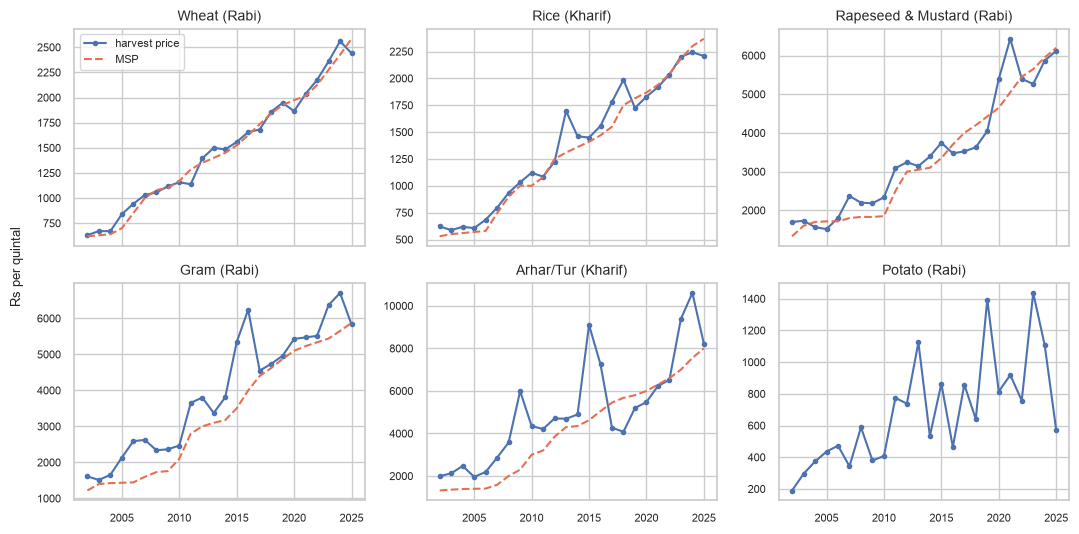

In [14]:
msp = pd.read_csv("data/processed/msp.csv")[["crop", "crop_year_start", "msp_rs_per_quintal"]]
shown = [("Wheat", "Rabi"), ("Rice", "Kharif"), ("Rapeseed & Mustard", "Rabi"), ("Gram", "Rabi"), ("Arhar/Tur", "Kharif"), ("Potato", "Rabi")]

fig, axes = plt.subplots(2, 3, figsize=(11, 5.5), sharex=True)
for ax, (crop, season) in zip(axes.ravel(), shown):
    line = state_harvest[(state_harvest["crop"] == crop) & (state_harvest["season"] == season)]
    ax.plot(line["crop_year_start"], line["state_harvest_price"], marker="o", ms=3, label="harvest price")
    support = msp[msp["crop"] == crop]
    support = support[support["crop_year_start"] >= line["crop_year_start"].min()]
    if len(support):
        ax.plot(support["crop_year_start"], support["msp_rs_per_quintal"], ls="--", color="#e76f51", label="MSP")
    ax.set_title(f"{crop} ({season})", fontsize=10)
    ax.tick_params(labelsize=8)
axes[0, 0].legend(fontsize=8)
fig.supylabel("Rs per quintal", fontsize=9)
plt.tight_layout()
plt.show()

### Year-on-year change of the state harvest price, by crop

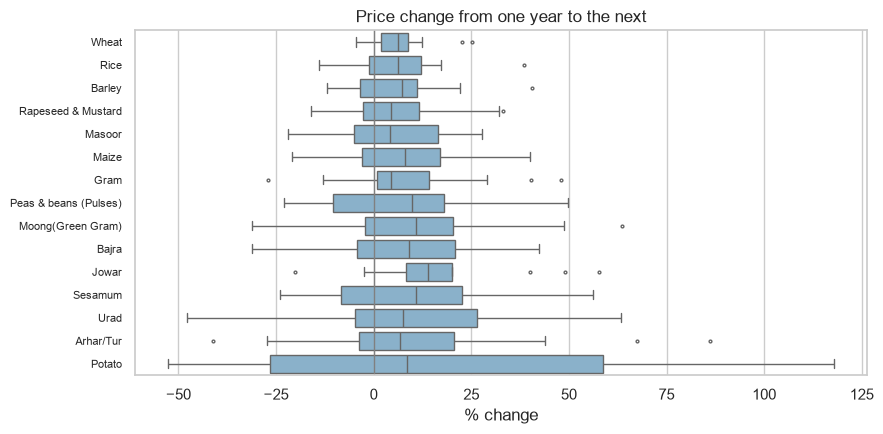

In [15]:
change = state_harvest.sort_values("crop_year_start").copy()
change["change_%"] = change.groupby(["crop", "season"])["state_harvest_price"].pct_change() * 100
order = change.groupby("crop")["change_%"].std().sort_values().index

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=change, y="crop", x="change_%", order=order, fliersize=2, color="#7fb3d5", ax=ax)
ax.axvline(0, color="grey", lw=1)
ax.set(title="Price change from one year to the next", xlabel="% change", ylabel="")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

### Pre-sowing price vs the harvest price that followed

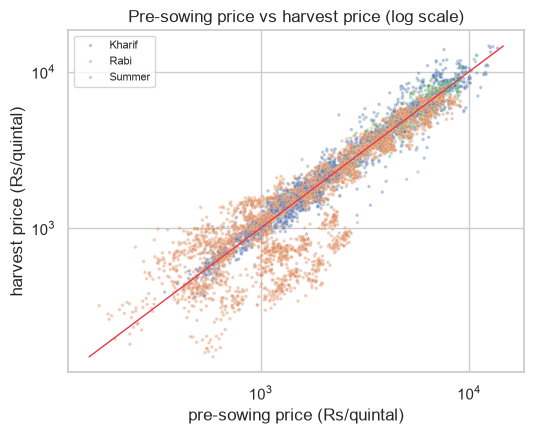

Correlation of the logs: 0.941


In [16]:
both = harvest.merge(presowing, on=["district", "crop", "season", "crop_year_start"])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.scatterplot(data=both, x="presowing_price", y="harvest_price", hue="season", s=6, alpha=0.4, ax=ax)
limits = [both["harvest_price"].min(), both["harvest_price"].max()]
ax.plot(limits, limits, color="#e63946", lw=1)
ax.set(xscale="log", yscale="log", title="Pre-sowing price vs harvest price (log scale)",
       xlabel="pre-sowing price (Rs/quintal)", ylabel="harvest price (Rs/quintal)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Correlation of the logs:", round(np.corrcoef(np.log(both["presowing_price"]), np.log(both["harvest_price"]))[0, 1], 3))

## Feature Engineering

### Add empty rows for the next season, for every district

In [17]:
keys = ["district", "crop", "season"]
last_year = int(harvest["crop_year_start"].max())
next_label = f"{last_year + 1}-{(last_year + 2) % 100:02d}"
all_districts = pd.read_csv("data/processed/district_master.csv")["district"]
next_rows = all_districts.to_frame().merge(crop_seasons, how="cross").assign(crop_year_start=last_year + 1)
table = pd.concat([harvest, next_rows], ignore_index=True)
print(f"{len(next_rows):,} district-crop-season rows added for {next_label}")

1,350 district-crop-season rows added for 2026-27


### Last year's harvest price (the district's, or the state's when the district has none)

In [18]:
def earlier(source, on, column, years_back, new_name):
    shifted = source[on + ["crop_year_start", column]].copy()
    shifted["crop_year_start"] += years_back
    return shifted.rename(columns={column: new_name})

state_keys = ["crop", "season"]
table = table.merge(earlier(harvest, keys, "harvest_price", 1, "district_last"), on=keys + ["crop_year_start"], how="left")
table = table.merge(earlier(harvest, keys, "harvest_price", 2, "district_last2"), on=keys + ["crop_year_start"], how="left")
table = table.merge(earlier(state_harvest, state_keys, "state_harvest_price", 1, "state_last"), on=state_keys + ["crop_year_start"], how="left")
table = table.merge(earlier(state_harvest, state_keys, "state_harvest_price", 2, "state_last2"), on=state_keys + ["crop_year_start"], how="left")

table["price_last_harvest"] = table["district_last"].fillna(table["state_last"])
table["last_is_district"] = table["district_last"].notna().astype(int)
table["district_vs_state_last"] = (table["district_last"] / table["state_last"]).fillna(1)
table["last_vs_year_before"] = (table["district_last"] / table["district_last2"]).fillna(table["state_last"] / table["state_last2"]).fillna(1)
table["state_last_vs_year_before"] = (table["state_last"] / table["state_last2"]).fillna(1)
table[["price_last_harvest", "last_is_district", "district_vs_state_last", "last_vs_year_before", "state_last_vs_year_before"]].describe().round(3)

,price_last_harvest,last_is_district,district_vs_state_last,last_vs_year_before,state_last_vs_year_before
count,11848.000,12187.000,12187.000,12187.000,12187.000
mean,3044.843,0.768,1.003,1.069,1.065
std,2369.746,0.422,0.096,0.249,0.235
min,131.154,0.000,0.533,0.336,0.474
25%,1248.014,1.000,0.974,0.964,0.966
50%,2166.185,1.000,1.000,1.040,1.043
75%,4540.421,1.000,1.027,1.140,1.132
max,14913.699,1.000,2.221,3.150,2.179


### Pre-sowing price relative to last year's harvest price

In [19]:
table = table.merge(presowing[keys + ["crop_year_start", "presowing_price"]], on=keys + ["crop_year_start"], how="left")
table = table.merge(state_presowing, on=state_keys + ["crop_year_start"], how="left")

table["presowing_known"] = table["presowing_price"].notna().astype(int) + table["state_presowing_price"].notna().astype(int)
table["presowing_vs_last"] = (table["presowing_price"].fillna(table["state_presowing_price"]) / table["price_last_harvest"]).fillna(1)
table["state_presowing_vs_last"] = (table["state_presowing_price"] / table["state_last"]).fillna(1)
table.groupby("presowing_known").size().rename({0: "no pre-sowing price", 1: "district or state price only", 2: "district and state price"})

presowing_known
no pre-sowing price              392
district or state price only    1990
district and state price        9805
dtype: int64

### MSP of the coming season

In [20]:
table = table.merge(msp.rename(columns={"msp_rs_per_quintal": "msp"}), on=["crop", "crop_year_start"], how="left")
table = table.merge(earlier(msp, ["crop"], "msp_rs_per_quintal", 1, "msp_last"), on=["crop", "crop_year_start"], how="left")
table = table.merge(earlier(msp, ["crop"], "msp_rs_per_quintal", 2, "msp_last2"), on=["crop", "crop_year_start"], how="left")

table["has_msp"] = table["msp_last"].notna().astype(int)
table["msp_growth"] = (table["msp"] / table["msp_last"]).fillna(table["msp_last"] / table["msp_last2"]).fillna(1)
table["last_price_vs_msp"] = (table["price_last_harvest"] / table["msp_last"]).fillna(1)
print("Crops without an MSP:", sorted(table.loc[table["has_msp"] == 0, "crop"].unique()))
table[["msp_growth", "last_price_vs_msp"]].describe().round(3)

Crops without an MSP: ['Peas & beans (Pulses)', 'Potato']


,msp_growth,last_price_vs_msp
count,12187.000,12187.000
mean,1.059,1.082
std,0.068,0.228
min,1.000,0.456
25%,1.012,0.992
50%,1.048,1.002
75%,1.071,1.130
max,1.741,3.348


### Last year's change in the state yield (supply)

In [21]:
yields = pd.read_csv("data/processed/master_table.csv", usecols=["crop", "season", "crop_year_start", "area_ha", "yield_t_per_ha"])
yields["crop"] = yields["crop"].str.replace(r"\s*&\s*", " & ", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()
state_yield = (yields[yields["area_ha"] >= 10].groupby(["crop", "season", "crop_year_start"], as_index=False)["yield_t_per_ha"].median()
               .rename(columns={"yield_t_per_ha": "state_yield"}))
table = table.merge(earlier(state_yield, state_keys, "state_yield", 1, "yield_last"), on=state_keys + ["crop_year_start"], how="left")
table = table.merge(earlier(state_yield, state_keys, "state_yield", 2, "yield_last2"), on=state_keys + ["crop_year_start"], how="left")
table["state_yield_change_last_year"] = (table["yield_last"] / table["yield_last2"]).fillna(1)
table["state_yield_change_last_year"].describe().round(3)

count    12187.000
mean         1.034
std          0.185
min          0.405
25%          0.974
50%          1.004
75%          1.075
max          3.399
Name: state_yield_change_last_year, dtype: float64

### Keep the features known before sowing

In [22]:
feature_cols = ["crop", "season", "crop_year_start", "price_last_harvest", "last_is_district", "district_vs_state_last",
                "last_vs_year_before", "state_last_vs_year_before", "presowing_known", "presowing_vs_last",
                "state_presowing_vs_last", "has_msp", "msp_growth", "last_price_vs_msp", "state_yield_change_last_year"]
table = table[["district", *feature_cols, "harvest_price", "harvest_price_records"]]

next_season = table[table["harvest_price"].isna()][["district", *feature_cols]].dropna().reset_index(drop=True)
data = table[table["harvest_price"].notna()]
before = len(data)
data = data.dropna(subset=feature_cols).sort_values("crop_year_start", kind="stable").reset_index(drop=True)
print(f"Next-season rows ({next_label}): {len(next_season):,}")
print(f"Dropped {before - len(data):,} rows with no price the year before -> {len(data):,} rows | nulls left: {data[feature_cols].isna().sum().sum()}")
data.groupby("crop_year_start").size().to_frame("rows").T

Next-season rows (2026-27): 1,275
Dropped 264 rows with no price the year before -> 10,573 rows | nulls left: 0


crop_year_start,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
rows,1,186,189,227,309,370,369,389,431,461,456,430,484,467,487,651,651,641,581,604,628,576,544,441


### Train/test split by year (train up to 2019, test 2020 onwards)

In [23]:
X, y = data[feature_cols], data["harvest_price"]

test_share = (data["crop_year_start"] >= 2020).mean()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_share, shuffle=False)
district_train, district_test = data.loc[X_train.index, "district"], data.loc[X_test.index, "district"]

print("Train:", X_train.shape, X_train["crop_year_start"].min(), "-", X_train["crop_year_start"].max())
print("Test: ", X_test.shape, X_test["crop_year_start"].min(), "-", X_test["crop_year_start"].max())

Train: (7199, 15) 2002 - 2019
Test:  (3374, 15) 2020 - 2025


### Target: price vs the change from last year's price

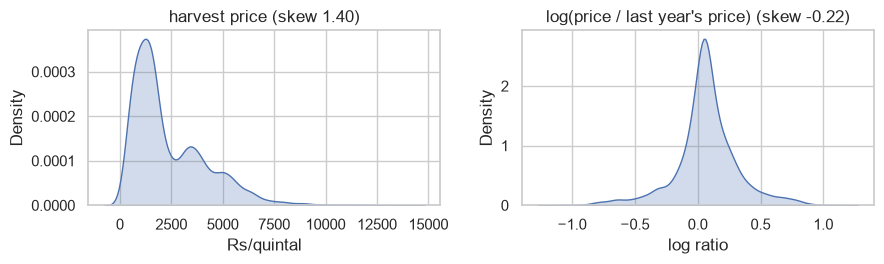

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
sns.kdeplot(y_train, fill=True, ax=axes[0])
axes[0].set(title=f"harvest price (skew {y_train.skew():.2f})", xlabel="Rs/quintal")
change_train = np.log(y_train / X_train["price_last_harvest"])
sns.kdeplot(change_train, fill=True, ax=axes[1])
axes[1].set(title=f"log(price / last year's price) (skew {change_train.skew():.2f})", xlabel="log ratio")
plt.tight_layout()
plt.show()

### Skewed amount features to log-transform (skew > 1, found on train)

In [25]:
cat_cols = ["crop", "season"]
flag_cols = ["last_is_district", "presowing_known", "has_msp"]
num_cols = [c for c in feature_cols if c not in cat_cols + flag_cols]

skew_before = X_train[num_cols].skew()
skewed = [c for c in num_cols if skew_before[c] > 1 and X_train[c].min() >= 0]
X_eda = X_train.copy()
X_eda[skewed] = np.log1p(X_eda[skewed])
pd.DataFrame({"skew_before": skew_before[skewed], "skew_after": X_eda[skewed].skew()}).round(2)

,skew_before,skew_after
price_last_harvest,1.46,-0.09
district_vs_state_last,1.60,0.83
last_vs_year_before,1.09,0.33
presowing_vs_last,1.73,1.13
state_presowing_vs_last,1.62,1.23
msp_growth,2.07,1.91
last_price_vs_msp,2.14,1.51
state_yield_change_last_year,3.08,1.17


### Correlation heatmap, with the price change

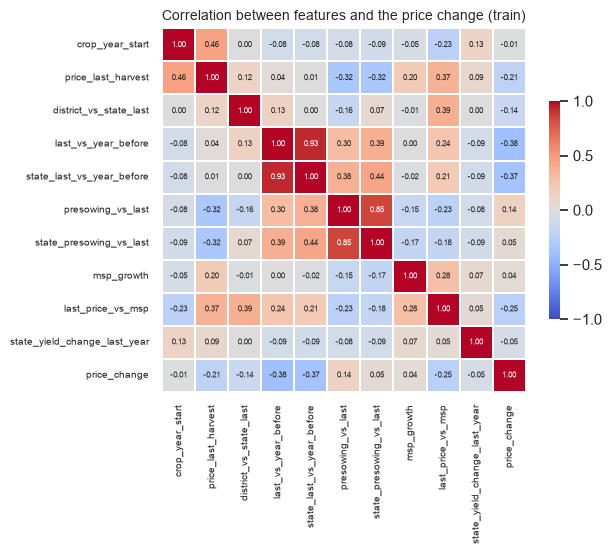

In [26]:
corr = X_eda[num_cols].assign(price_change=change_train).corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 6},
            square=True, linewidths=0.3, cbar_kws={"shrink": 0.6}, ax=ax)
ax.set_title("Correlation between features and the price change (train)", fontsize=10)
ax.tick_params(labelsize=7)
plt.tight_layout()
plt.show()

### Essential features and features to drop (one from each pair above 0.95)

In [27]:
essential = ["crop", "season", "crop_year_start", "price_last_harvest", "presowing_vs_last", "msp_growth"]

pairs = corr.drop(index="price_change", columns="price_change")
pairs = pairs.where(np.triu(np.ones(pairs.shape, dtype=bool), k=1)).stack()
to_drop = []
for (first, second), r in pairs[pairs.abs() > 0.95].items():
    if first not in to_drop and second not in to_drop:
        candidate = first if second in essential else second
        if candidate not in essential:
            to_drop.append(candidate)
model_columns = [c for c in feature_cols if c not in to_drop]
print("Pairs above 0.95:", pairs[pairs.abs() > 0.95].round(3).to_dict())
print("Dropped:", to_drop, "|", len(model_columns), "features used")

Pairs above 0.95: {}
Dropped: [] | 15 features used


### ColumnTransformer: log, scale, one-hot (fitted on train)

In [28]:
def make_preprocessor(columns):
    numeric = [c for c in columns if c not in cat_cols + flag_cols]
    return ColumnTransformer(
        [("log_scale", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                                 ("scale", StandardScaler())]), [c for c in numeric if c in skewed]),
         ("scale", StandardScaler(), [c for c in numeric if c not in skewed]),
         ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), [c for c in columns if c in cat_cols]),
         ("flag", "passthrough", [c for c in columns if c in flag_cols])],
        remainder="drop",
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

X_train_prep = make_preprocessor(model_columns).fit_transform(X_train)
print("X_train_prep:", X_train_prep.shape, "| nulls:", X_train_prep.isna().sum().sum())
X_train_prep[[c for c in num_cols if c in model_columns]].describe().loc[["mean", "std"]].round(2)

X_train_prep: (7199, 31) | nulls: 0


,crop_year_start,price_last_harvest,district_vs_state_last,last_vs_year_before,state_last_vs_year_before,presowing_vs_last,state_presowing_vs_last,msp_growth,last_price_vs_msp,state_yield_change_last_year
mean,0.0,0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## Model B: Price Model

### Evaluation metrics

In [29]:
def evaluate(name, predict):
    pred_train, pred = np.asarray(predict(X_train)), np.asarray(predict(X_test))
    ape = np.abs(pred - y_test) / y_test
    return {
        "model": name,
        "train_R2": r2_score(y_train, pred_train),
        "test_R2": r2_score(y_test, pred),
        "MAE_rs_per_quintal": mean_absolute_error(y_test, pred),
        "MAPE_%": ape.mean() * 100,
        "median_APE_%": ape.median() * 100,
        "accuracy_within_10%": (ape <= 0.10).mean() * 100,
        "accuracy_within_20%": (ape <= 0.20).mean() * 100,
    }

### Cross-validation folds: by year and by district

In [30]:
years = X_train["crop_year_start"].to_numpy()
year_folds = [(np.where(years < start)[0], np.where((years >= start) & (years <= start + 2))[0])
              for start in (2011, 2014, 2017)]
district_folds = list(GroupKFold(n_splits=5).split(X_train, groups=district_train))

def cv_scores(estimator, folds):
    rows = []
    for fit_idx, val_idx in folds:
        X_val, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]
        if estimator is None:
            pred = X_val["price_last_harvest"]
        else:
            pred = clone(estimator).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx]).predict(X_val)
        ape = np.abs(np.asarray(pred) - y_val) / y_val
        rows.append({"accuracy_within_20%": (ape <= 0.20).mean() * 100, "accuracy_within_10%": (ape <= 0.10).mean() * 100,
                     "MAPE_%": ape.mean() * 100})
    return pd.DataFrame(rows)

for fit_idx, val_idx in year_folds:
    print(f"Year fold: train {years[fit_idx].min()}-{years[fit_idx].max()} ({len(fit_idx):,} rows) | validate {years[val_idx].min()}-{years[val_idx].max()} ({len(val_idx):,} rows)")
print("District folds: 5 folds, each validates on", district_train.iloc[district_folds[0][1]].nunique(), "districts the model never saw")

Year fold: train 2002-2010 (2,471 rows) | validate 2011-2013 (1,347 rows)
Year fold: train 2002-2013 (3,818 rows) | validate 2014-2016 (1,438 rows)
Year fold: train 2002-2016 (5,256 rows) | validate 2017-2019 (1,943 rows)
District folds: 5 folds, each validates on 14 districts the model never saw


### Baselines

In [31]:
def last_year_baseline(X):
    return X["price_last_harvest"].to_numpy()

def msp_baseline(X):
    return (X["price_last_harvest"] * X["msp_growth"]).to_numpy()

def presowing_baseline(X):
    return (X["price_last_harvest"] * X["presowing_vs_last"]).to_numpy()

LAST_YEAR_BASELINE = "Baseline: last year's harvest price"
results = [{**evaluate(LAST_YEAR_BASELINE, last_year_baseline),
            "cv_accuracy_within_20%": cv_scores(None, year_folds)["accuracy_within_20%"].mean()},
           evaluate("Baseline: last year's price x MSP growth", msp_baseline),
           evaluate("Baseline: pre-sowing price", presowing_baseline)]
pd.DataFrame(results).set_index("model").round(2)

,train_R2,test_R2,MAE_rs_per_quintal,MAPE_%,median_APE_%,accuracy_within_10%,accuracy_within_20%,cv_accuracy_within_20%
model,,,,,,,,
Baseline: last year's harvest price,0.82,0.94,454.48,14.37,9.06,54.30,79.46,67.31
Baseline: last year's price x MSP growth,0.79,0.94,428.35,14.00,8.23,56.64,79.19,NaN
Baseline: pre-sowing price,0.89,0.95,401.40,17.51,7.18,60.94,83.14,NaN


### Model pipelines

In [32]:
def build(model, target, columns=None):
    pipeline = Pipeline([("prep", make_preprocessor(columns or model_columns)), ("model", model)])
    if target == "log":
        return TransformedTargetRegressor(regressor=pipeline, func=np.log, inverse_func=np.exp)
    return HistoryAdjustedRegressor(regressor=pipeline, reference_col="price_last_harvest")

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=3, max_features=0.5,
                                           n_jobs=-1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=5, subsample=0.8, colsample_bytree=0.7,
                            objective="reg:absoluteerror", n_jobs=-1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=31, min_child_samples=40, subsample=0.8,
                              subsample_freq=1, colsample_bytree=0.7, objective="l1", random_state=42, verbose=-1),
}
TARGETS = {"log": "log target", "history": "change from last year"}
build(models["LightGBM"], "history")

,regressor,Pipeline(step...verbose=-1))])
,reference_col,'price_last_harvest'
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log_scale', ...), ('scale', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights tran

### Train and evaluate every model (log price and change from last year's price)

In [33]:
for name, model in models.items():
    for target, label in TARGETS.items():
        estimator = build(clone(model), target)
        fitted = clone(estimator).fit(X_train, y_train)
        results.append({**evaluate(f"{name} ({label})", fitted.predict),
                        "cv_accuracy_within_20%": cv_scores(estimator, year_folds)["accuracy_within_20%"].mean()})

def results_table():
    out = pd.DataFrame(results).set_index("model")
    return out[["cv_accuracy_within_20%"] + [c for c in out.columns if c != "cv_accuracy_within_20%"]].round(3)

comparison = results_table()
comparison.sort_values("cv_accuracy_within_20%", ascending=False)

,cv_accuracy_within_20%,train_R2,test_R2,MAE_rs_per_quintal,MAPE_%,median_APE_%,accuracy_within_10%,accuracy_within_20%
model,,,,,,,,
XGBoost (change from last year),78.886,0.973,0.959,346.250,11.777,6.040,68.672,88.234
Random Forest (change from last year),78.851,0.983,0.957,348.288,11.529,6.244,66.983,87.048
LightGBM (change from last year),77.357,0.970,0.959,353.685,12.073,6.392,66.894,86.633
LightGBM (log target),71.054,0.968,0.861,647.078,14.560,11.902,41.820,77.682
XGBoost (log target),70.575,0.975,0.871,601.135,13.829,9.995,50.030,78.364
Baseline: last year's harvest price,67.314,0.816,0.938,454.476,14.368,9.061,54.298,79.461
Random Forest (log target),67.120,0.982,0.836,713.382,17.111,14.083,34.469,68.880
Linear Regression (change from last year),62.880,0.883,0.936,519.523,17.875,12.921,37.908,73.533
Linear Regression (log target),62.840,0.883,0.936,519.926,17.877,12.926,37.848,73.503


### Model comparison

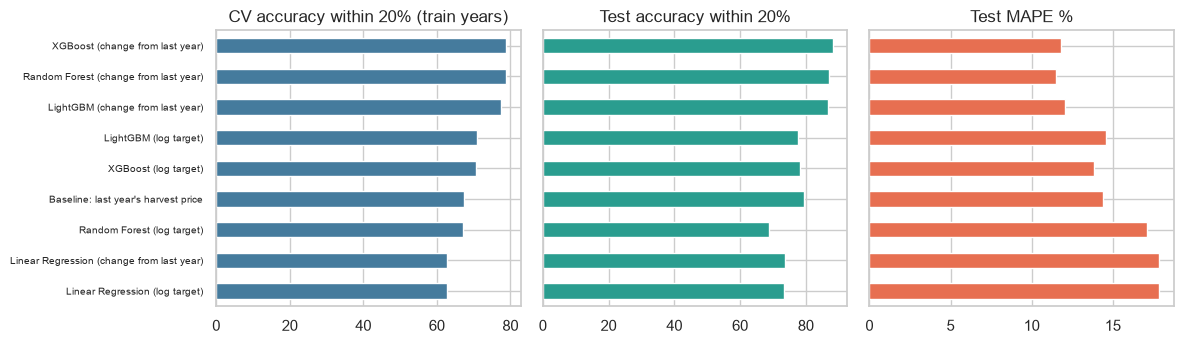

In [34]:
plot = comparison.dropna(subset=["cv_accuracy_within_20%"]).sort_values("cv_accuracy_within_20%")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
titles = {"cv_accuracy_within_20%": "CV accuracy within 20% (train years)", "accuracy_within_20%": "Test accuracy within 20%", "MAPE_%": "Test MAPE %"}
for ax, metric, color in zip(axes, titles, ["#457b9d", "#2a9d8f", "#e76f51"]):
    plot[metric].plot.barh(ax=ax, color=color)
    ax.set(title=titles[metric], ylabel="")
    ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

### Choose the model by cross-validated accuracy within 20%, then tune it

In [35]:
best_name = comparison["cv_accuracy_within_20%"].drop(index=LAST_YEAR_BASELINE).idxmax()
family = best_name.split(" (")[0]
best_target = "log" if "log target" in best_name else "history"
print("Best model by cross-validation:", best_name)

within_20 = make_scorer(lambda y_true, y_hat: np.mean(np.abs(y_hat - y_true) / y_true <= 0.20))
grids = {
    "LightGBM": {"n_estimators": [300, 500, 800], "learning_rate": [0.02, 0.03, 0.05], "num_leaves": [15, 31, 63],
                 "min_child_samples": [20, 40, 80], "colsample_bytree": [0.5, 0.7, 0.9], "reg_lambda": [0, 1, 5],
                 "objective": ["l1", "huber"]},
    "XGBoost": {"n_estimators": [300, 500, 800], "learning_rate": [0.02, 0.03, 0.05], "max_depth": [4, 5, 7],
                "min_child_weight": [1, 5, 10], "colsample_bytree": [0.5, 0.7, 0.9], "reg_lambda": [0, 1, 5]},
    "Random Forest": {"n_estimators": [200, 400], "max_features": [0.3, 0.5, 0.7], "min_samples_leaf": [1, 3, 5]},
    "Linear Regression": {"fit_intercept": [True]},
}
search = RandomizedSearchCV(
    build(clone(models[family]), best_target),
    {"regressor__model__" + k: v for k, v in grids[family].items()},
    n_iter={"LightGBM": 12, "XGBoost": 12, "Random Forest": 6, "Linear Regression": 1}[family],
    cv=year_folds, scoring=within_20, random_state=42, n_jobs=1,
).fit(X_train, y_train)

tuned_cv, default_cv = search.best_score_ * 100, comparison.loc[best_name, "cv_accuracy_within_20%"]
best_model = clone(search.best_estimator_.regressor.named_steps["model"]) if tuned_cv > default_cv else clone(models[family])
print("Best parameters:", {k.replace("regressor__model__", ""): v for k, v in search.best_params_.items()})
print(f"CV accuracy within 20%: default {default_cv:.2f} | tuned {tuned_cv:.2f} ->", "tuned" if tuned_cv > default_cv else "default", "settings kept")

Best model by cross-validation: XGBoost (change from last year)


Best parameters: {'reg_lambda': 1, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 0.7}
CV accuracy within 20%: default 78.89 | tuned 78.89 -> default settings kept


### Cross-validation of the feature sets

In [36]:
def cv_summary(columns):
    estimator = build(clone(best_model), best_target, columns)
    by_year, by_district = cv_scores(estimator, year_folds), cv_scores(estimator, district_folds)
    return {"features": len(columns),
            "year_cv_accuracy_20%": by_year["accuracy_within_20%"].mean(), "year_cv_MAPE_%": by_year["MAPE_%"].mean(),
            "district_cv_accuracy_20%": by_district["accuracy_within_20%"].mean(), "district_cv_MAPE_%": by_district["MAPE_%"].mean()}

feature_sets = {
    "All features": model_columns,
    "Without the pre-sowing price": [c for c in model_columns if "presowing" not in c],
    "Without the MSP": [c for c in model_columns if "msp" not in c],
    "Without the state yield change": [c for c in model_columns if c != "state_yield_change_last_year"],
    "Essential only": essential,
}
set_scores = pd.DataFrame({name: cv_summary(cols) for name, cols in feature_sets.items()}).T
set_scores.round(2)

,features,year_cv_accuracy_20%,year_cv_MAPE_%,district_cv_accuracy_20%,district_cv_MAPE_%
All features,15.0,78.89,13.88,94.36,6.50
Without the pre-sowing price,12.0,70.25,17.96,92.81,7.14
Without the MSP,12.0,77.77,14.54,94.03,6.65
Without the state yield change,14.0,78.49,13.36,94.08,6.62
Essential only,6.0,74.18,17.20,92.03,7.72


### Model B: final features, trained up to 2019, tested on 2020 onwards

In [37]:
candidates = set_scores.drop(index=["Without the pre-sowing price", "Essential only"])
model_b_columns = feature_sets[candidates["year_cv_accuracy_20%"].idxmax()]

MODEL_B = f"Model B: {family} ({TARGETS[best_target]}), {len(model_b_columns)} features"
model_b_estimator = build(clone(best_model), best_target, model_b_columns)
model_b = clone(model_b_estimator).fit(X_train, y_train)
model_b_pred = pd.Series(model_b.predict(X_test), index=X_test.index)
results.append({**evaluate(MODEL_B, model_b.predict),
                "cv_accuracy_within_20%": cv_scores(model_b_estimator, year_folds)["accuracy_within_20%"].mean()})
comparison = results_table()
print("Model B features:", model_b_columns)
comparison.loc[[LAST_YEAR_BASELINE, "Baseline: last year's price x MSP growth", "Baseline: pre-sowing price", best_name, MODEL_B]]

Model B features: ['crop', 'season', 'crop_year_start', 'price_last_harvest', 'last_is_district', 'district_vs_state_last', 'last_vs_year_before', 'state_last_vs_year_before', 'presowing_known', 'presowing_vs_last', 'state_presowing_vs_last', 'has_msp', 'msp_growth', 'last_price_vs_msp', 'state_yield_change_last_year']


,cv_accuracy_within_20%,train_R2,test_R2,MAE_rs_per_quintal,MAPE_%,median_APE_%,accuracy_within_10%,accuracy_within_20%
model,,,,,,,,
Baseline: last year's harvest price,67.314,0.816,0.938,454.476,14.368,9.061,54.298,79.461
Baseline: last year's price x MSP growth,NaN,0.788,0.943,428.349,13.998,8.232,56.639,79.194
Baseline: pre-sowing price,NaN,0.890,0.949,401.402,17.510,7.182,60.937,83.136
XGBoost (change from last year),78.886,0.973,0.959,346.250,11.777,6.040,68.672,88.234
"Model B: XGBoost (change from last year), 15 features",78.886,0.973,0.959,346.250,11.777,6.040,68.672,88.234


### Cross-validation of Model B: every fold

In [38]:
by_year = cv_scores(model_b_estimator, year_folds)
by_year.index = [f"validate {years[val].min()}-{years[val].max()}" for _, val in year_folds]
by_district = cv_scores(model_b_estimator, district_folds)
by_district.index = [f"unseen districts, fold {i}" for i in range(1, 6)]
display(pd.concat([by_year, by_district]).round(2))

test_error = (model_b_pred - y_test).abs() / y_test
for label, folds in [("By year", by_year), ("By district", by_district)]:
    print(f"{label}: accuracy within 20% = {folds['accuracy_within_20%'].mean():.1f} ± {folds['accuracy_within_20%'].std():.1f} | "
          f"MAPE = {folds['MAPE_%'].mean():.1f} ± {folds['MAPE_%'].std():.1f}")
print(f"Test years: accuracy within 20% = {(test_error <= 0.20).mean() * 100:.1f} | within 10% = {(test_error <= 0.10).mean() * 100:.1f} | MAPE = {test_error.mean() * 100:.1f}")

,accuracy_within_20%,accuracy_within_10%,MAPE_%
validate 2011-2013,78.77,56.42,12.38
validate 2014-2016,73.23,51.32,18.04
validate 2017-2019,84.66,59.24,11.22
"unseen districts, fold 1",95.68,83.69,5.96
"unseen districts, fold 2",92.77,76.08,7.48
"unseen districts, fold 3",94.07,81.17,6.32
"unseen districts, fold 4",94.38,81.41,6.57
"unseen districts, fold 5",94.91,82.08,6.20


By year: accuracy within 20% = 78.9 ± 5.7 | MAPE = 13.9 ± 3.7
By district: accuracy within 20% = 94.4 ± 1.1 | MAPE = 6.5 ± 0.6
Test years: accuracy within 20% = 88.2 | within 10% = 68.7 | MAPE = 11.8


### Predicted vs actual harvest price (test years)

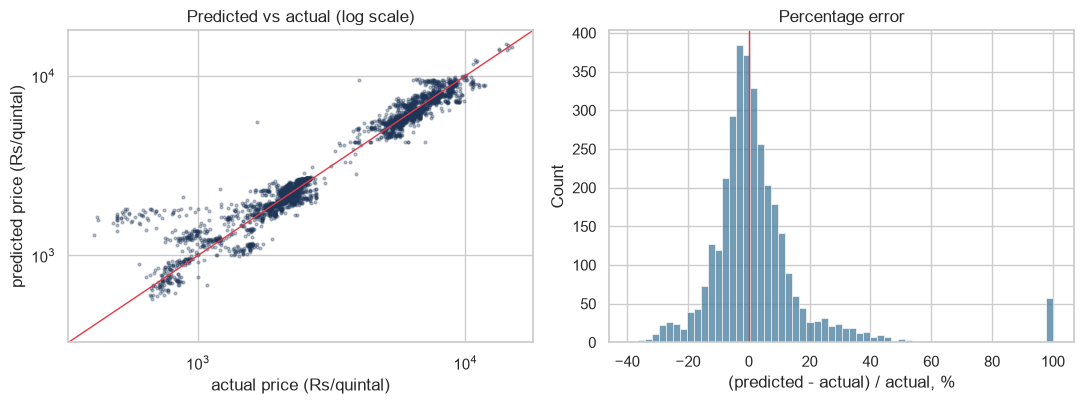

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(y_test, model_b_pred, s=4, alpha=0.3, color="#1d3557")
limits = [y_test.min() * 0.8, y_test.max() * 1.2]
axes[0].plot(limits, limits, color="#e63946", lw=1)
axes[0].set(xscale="log", yscale="log", xlim=limits, ylim=limits, title="Predicted vs actual (log scale)",
            xlabel="actual price (Rs/quintal)", ylabel="predicted price (Rs/quintal)")
sns.histplot(((model_b_pred - y_test) / y_test * 100).clip(-100, 100), bins=60, ax=axes[1], color="#457b9d")
axes[1].axvline(0, color="#e63946", lw=1)
axes[1].set(title="Percentage error", xlabel="(predicted - actual) / actual, %")
plt.tight_layout()
plt.show()

### Error by crop, next to the last-year baseline

In [40]:
baseline_error = (X_test["price_last_harvest"] - y_test).abs() / y_test
crop_test = X_test["crop"]
by_crop = pd.DataFrame({"rows": crop_test.groupby(crop_test).size(),
                        "actual_median_price": y_test.groupby(crop_test).median(),
                        "MAPE_%": test_error.groupby(crop_test).mean() * 100,
                        "accuracy_within_10%": (test_error <= 0.1).groupby(crop_test).mean() * 100,
                        "accuracy_within_20%": (test_error <= 0.2).groupby(crop_test).mean() * 100,
                        "baseline_accuracy_within_20%": (baseline_error <= 0.2).groupby(crop_test).mean() * 100}).round(1)
by_crop.sort_values("accuracy_within_20%", ascending=False)

,rows,actual_median_price,MAPE_%,accuracy_within_10%,accuracy_within_20%,baseline_accuracy_within_20%
crop,,,,,,
Masoor,185,6759.3,4.7,94.1,100.0,95.7
Wheat,415,2317.7,5.2,83.6,100.0,100.0
Rapeseed & Mustard,346,5623.8,7.9,68.5,97.7,72.5
Rice,290,2056.5,6.4,72.1,97.2,97.6
Gram,312,5760.2,5.7,83.7,97.1,99.7
Urad,272,8040.4,6.2,81.2,96.7,89.0
Barley,152,2169.4,8.6,67.1,94.1,76.3
Maize,361,2100.0,8.6,75.6,88.1,75.1
Moong(Green Gram),261,7755.0,10.2,66.7,86.6,95.4


### Error by test year

In [41]:
year_test = X_test["crop_year_start"]
pd.DataFrame({"rows": year_test.groupby(year_test).size(),
              "MAPE_%": test_error.groupby(year_test).mean() * 100,
              "accuracy_within_20%": (test_error <= 0.2).groupby(year_test).mean() * 100,
              "baseline_accuracy_within_20%": (baseline_error <= 0.2).groupby(year_test).mean() * 100}).round(1)

,rows,MAPE_%,accuracy_within_20%,baseline_accuracy_within_20%
crop_year_start,,,,
2020,581,8.5,90.9,64.7
2021,604,10.7,86.3,85.1
2022,628,7.7,96.5,81.5
2023,576,8.4,85.4,82.1
2024,544,7.5,94.7,85.3
2025,441,33.1,71.4,77.6


### Reliable crops: chosen by cross-validation on the training years

In [42]:
out_of_fold = []
for fit_idx, val_idx in year_folds:
    fold_model = clone(model_b_estimator).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
    out_of_fold.append(pd.Series(fold_model.predict(X_train.iloc[val_idx]), index=X_train.index[val_idx]))
out_of_fold = pd.concat(out_of_fold)
cv_ok = (out_of_fold - y_train.loc[out_of_fold.index]).abs() / y_train.loc[out_of_fold.index] <= 0.20
cv_crop = cv_ok.groupby(X_train.loc[out_of_fold.index, "crop"])

reliability = pd.DataFrame({"cv_rows": cv_crop.size(), "cv_accuracy_within_20%": cv_crop.mean() * 100,
                            "test_accuracy_within_20%": (test_error <= 0.2).groupby(crop_test).mean() * 100})
reliability["reliable"] = (reliability["cv_accuracy_within_20%"] >= 70) & (reliability["cv_rows"] >= 100)
reliable_crops = reliability.index[reliability["reliable"]].tolist()
tier = crop_test.isin(reliable_crops).map({True: "reliable crops", False: "other crops"})
display(reliability.sort_values("cv_accuracy_within_20%", ascending=False).round(1))
pd.DataFrame({"crops": crop_test.groupby(tier).nunique(), "rows": test_error.groupby(tier).size(),
              "accuracy_within_20%": (test_error <= 0.2).groupby(tier).mean() * 100,
              "MAPE_%": test_error.groupby(tier).mean() * 100}).round(1)

,cv_rows,cv_accuracy_within_20%,test_accuracy_within_20%,reliable
crop,,,,
Wheat,600,100.0,100.0,True
Barley,220,97.3,94.1,True
Rice,450,92.2,97.2,True
Rapeseed & Mustard,566,91.5,97.7,True
Maize,478,89.1,88.1,True
Moong(Green Gram),259,84.6,86.6,True
Masoor,202,83.7,100.0,True
Gram,456,82.9,97.1,True
Bajra,134,81.3,75.5,True


,crops,rows,accuracy_within_20%,MAPE_%
crop,,,,
other crops,5,839,71.8,24.1
reliable crops,10,2535,93.7,7.7


### Permutation importance (test years)

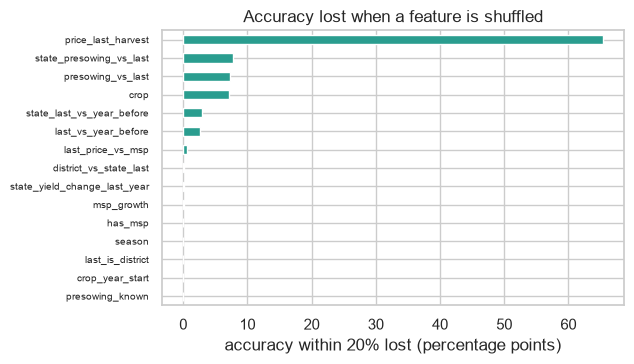

In [43]:
perm = permutation_importance(model_b, X_test[model_b_columns], y_test, n_repeats=5, random_state=42,
                              scoring=within_20, n_jobs=1)
importance = pd.Series(perm.importances_mean * 100, index=model_b_columns).sort_values()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
importance.plot.barh(ax=ax, color="#2a9d8f")
ax.set(title="Accuracy lost when a feature is shuffled", xlabel="accuracy within 20% lost (percentage points)")
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

### Prediction ranges: an 80% range per crop from cross-validation errors

In [44]:
cv_error = np.log(y_train.loc[out_of_fold.index] / out_of_fold)
cv_error_crop = X_train.loc[out_of_fold.index, "crop"]
pooled = cv_error.quantile([0.10, 0.90])
crop_range = cv_error.groupby(cv_error_crop).quantile([0.10, 0.90]).unstack()
crop_range.loc[cv_error.groupby(cv_error_crop).size() < 100] = pooled.to_numpy()

range_low = model_b_pred * np.exp(crop_test.map(crop_range[0.10]).fillna(pooled[0.10]))
range_high = model_b_pred * np.exp(crop_test.map(crop_range[0.90]).fillna(pooled[0.90]))
inside = (y_test >= range_low) & (y_test <= range_high)

print(f"Actual price inside the predicted range: {inside.mean():.1%} of test rows")
pd.DataFrame({"range_low_%": (np.exp(crop_range[0.10]) - 1) * 100, "range_high_%": (np.exp(crop_range[0.90]) - 1) * 100,
              "test_rows": inside.groupby(crop_test).size(), "inside_range_%": inside.groupby(crop_test).mean() * 100}).round(1).sort_values("range_high_%")

Actual price inside the predicted range: 81.7% of test rows


,range_low_%,range_high_%,test_rows,inside_range_%
crop,,,,
Wheat,-2.3,6.9,415,40.5
Rapeseed & Mustard,-14.4,10.7,346,76.6
Barley,-10.6,15.0,152,77.6
Rice,-7.4,15.6,290,88.6
Moong(Green Gram),-19.3,16.4,261,89.3
Maize,-14.9,16.7,361,86.4
Masoor,-17.4,19.3,185,100.0
Bajra,-17.5,23.4,110,70.9
Gram,-12.8,25.6,312,93.6


### Sanity check: prediction and range for one district, season and year

In [45]:
def price_table(district, season, year):
    rows = X_test[(district_test == district) & (X_test["season"] == season) & (X_test["crop_year_start"] == year)]
    out = pd.DataFrame({"crop": rows["crop"], "last_year_price": rows["price_last_harvest"].round(0),
                        "predicted_price": model_b_pred.loc[rows.index].round(0),
                        "range_low": range_low.loc[rows.index].round(0), "range_high": range_high.loc[rows.index].round(0),
                        "actual_price": y_test.loc[rows.index].round(0)})
    return out.sort_values("predicted_price", ascending=False).reset_index(drop=True)

price_table("Agra", "Rabi", 2024)

,crop,last_year_price,predicted_price,range_low,range_high,actual_price
0,Gram,6371.0,7682.0,6699.0,9646.0,6536.0
1,Masoor,6589.0,6506.0,5372.0,7761.0,6959.0
2,Rapeseed & Mustard,5119.0,5577.0,4772.0,6173.0,5943.0
3,Wheat,2376.0,2702.0,2641.0,2890.0,2559.0
4,Barley,2088.0,2507.0,2241.0,2882.0,2415.0
5,Potato,1387.0,1132.0,640.0,1870.0,1047.0


In [46]:
price_table("Gorakhpur", "Kharif", 2024)

,crop,last_year_price,predicted_price,range_low,range_high,actual_price
0,Urad,8640.0,9085.0,6728.0,11997.0,9078.0
1,Moong(Green Gram),8632.0,8612.0,6953.0,10026.0,8717.0
2,Maize,2109.0,2265.0,1928.0,2643.0,2456.0
3,Rice,2126.0,2253.0,2085.0,2604.0,2291.0


### Final model: trained on the last 15 years only
The model that makes the predictions is trained on the most recent 15 years, so that it reflects recent farming conditions. Check on the test years: the same settings trained on the last 15 training years, next to the model trained on every training year.

In [47]:
FINAL_TRAIN_YEARS = 15

window_start = int(X_train["crop_year_start"].max()) - FINAL_TRAIN_YEARS + 1
in_window = X_train["crop_year_start"] >= window_start
window_model = clone(model_b_estimator).fit(X_train[in_window], y_train[in_window])
window_error = (window_model.predict(X_test) - y_test).abs() / y_test
all_error = (model_b_pred - y_test).abs() / y_test

window_check = pd.DataFrame({
    "train_years": [f"{int(X_train['crop_year_start'].min())}-{int(X_train['crop_year_start'].max())}",
                    f"{window_start}-{int(X_train['crop_year_start'].max())}"],
    "train_rows": [len(X_train), int(in_window.sum())],
    "accuracy_within_20%": [(all_error <= 0.20).mean() * 100, (window_error <= 0.20).mean() * 100],
    "MAPE_%": [all_error.mean() * 100, window_error.mean() * 100],
}, index=["Model B, every training year", "Model B, last {} training years".format(FINAL_TRAIN_YEARS)])
window_check.round(1)

,train_years,train_rows,accuracy_within_20%,MAPE_%
"Model B, every training year",2002-2019,7199,88.2,11.8
"Model B, last 15 training years",2005-2019,6823,88.1,11.7


## Save Model B

### Retrain on all years and save the model with everything the interface needs

In [48]:
def prediction_table(pred, actual, district, sample):
    rows = X.loc[pred.index]
    return pd.DataFrame({"district": district.loc[pred.index], "crop": rows["crop"], "season": rows["season"],
                         "crop_year_start": rows["crop_year_start"], "sample": sample,
                         "actual": actual.loc[pred.index], "predicted": pred})

past_predictions = pd.concat([prediction_table(out_of_fold, y_train, district_train, "cross-validation"),
                              prediction_table(model_b_pred, y_test, district_test, "test")], ignore_index=True)

recent = X["crop_year_start"] > X["crop_year_start"].max() - FINAL_TRAIN_YEARS
deployed_model = clone(model_b_estimator).fit(X[recent], y[recent])

bundle = {
    "model": deployed_model,
    "feature_columns": model_b_columns,
    "next_season": next_season,
    "next_season_label": next_label,
    "crop_range": crop_range.rename(columns={0.10: "low", 0.90: "high"}),
    "pooled_range": {"low": float(pooled[0.10]), "high": float(pooled[0.90])},
    "reliable_crops": reliable_crops,
    "past_predictions": past_predictions,
    "trained_on_years": (int(X.loc[recent, "crop_year_start"].min()), int(X["crop_year_start"].max())),
    "window_check": window_check.round(1).to_dict("index"),
    "test_metrics": {"test_years": f"{int(X_test['crop_year_start'].min())}-{int(X_test['crop_year_start'].max())}",
                     "accuracy_within_20%": round(float((test_error <= 0.20).mean() * 100), 1),
                     "accuracy_within_10%": round(float((test_error <= 0.10).mean() * 100), 1),
                     "MAPE_%": round(float(test_error.mean() * 100), 1),
                     "inside_80%_range_%": round(float(inside.mean() * 100), 1)},
}
Path("models").mkdir(exist_ok=True)
joblib.dump(bundle, "models/model_b.joblib")
print("Saved models/model_b.joblib:", round(Path("models/model_b.joblib").stat().st_size / 1e6, 1), "MB")
print("Trained on", bundle["trained_on_years"], "| predicts", next_label, "|", bundle["test_metrics"])

Saved models/model_b.joblib: 2.1 MB
Trained on (2011, 2025) | predicts 2026-27 | {'test_years': '2020-2025', 'accuracy_within_20%': 88.2, 'accuracy_within_10%': 68.7, 'MAPE_%': 11.8, 'inside_80%_range_%': 81.7}


### Check the saved model through the interface functions

In [49]:
predict_prices("Agra", "Rabi")

,price_year,last_harvest_price,predicted_price,price_range_low,price_range_high,price_basis,price_reliable
crop,,,,,,,
Gram,2026-27,6644.0,7664.0,6684.0,9623.0,district mandis,True
Rapeseed & Mustard,2026-27,6488.0,7102.0,6077.0,7861.0,district mandis,True
Masoor,2026-27,6841.0,6954.0,5742.0,8295.0,state average,True
Peas & beans (Pulses),2026-27,7036.0,6703.0,5664.0,8762.0,district mandis,True
Wheat,2026-27,2406.0,2585.0,2526.0,2765.0,district mandis,True
Barley,2026-27,2145.0,2327.0,2080.0,2675.0,state average,True
Maize,2026-27,1867.0,2202.0,1875.0,2570.0,state average,True
Potato,2026-27,517.0,730.0,413.0,1206.0,district mandis,False


In [50]:
recommend_crops("Agra", "Rabi", farmer_yields={"Wheat": 3.6})

,yield_year,farm_predicted_t_ha,farm_range_low_t_ha,farm_range_high_t_ha,yield_reliable,basis,sold_t_ha,price_year,predicted_price,price_range_low,price_range_high,price_reliable,price_basis,revenue_rs_per_ha,byproduct_rs_per_ha,cost_year,cost_rs_per_ha,cost_reliable,profit_rs_per_ha,profit_range_low,profit_range_high,suitable,advice
crop,,,,,,,,,,,,,,,,,,,,,,,
Peas & beans (Pulses),2025-26,2.12,1.39,2.94,False,farmer's other crops,2.12,2026-27,6703.0,5664.0,8762.0,True,district mandis,142100.0,8500.0,2026-27,50700.0,False,99900.0,31700.0,170800.0,True,rarely grown here (under 1% of the district's ...
Rapeseed & Mustard,2025-26,1.68,1.16,2.16,False,farmer's other crops,1.68,2026-27,7102.0,6077.0,7861.0,True,district mandis,119300.0,8000.0,2026-27,51600.0,True,75700.0,29500.0,114500.0,True,needs irrigation
Gram,2025-26,1.45,0.62,2.48,False,farmer's other crops,1.45,2026-27,7664.0,6684.0,9623.0,True,district mandis,111100.0,6800.0,2026-27,48400.0,True,69500.0,6100.0,155200.0,True,rarely grown here (under 1% of the district's ...
Potato,2025-26,31.29,23.68,40.40,False,farmer's other crops,31.29,2026-27,730.0,413.0,1206.0,False,district mandis,228400.0,0.0,2026-27,167000.0,False,61400.0,-55300.0,228300.0,True,needs irrigation; official yield data ends 202...
Wheat,2025-26,3.58,2.61,4.31,True,farmer's own yield,3.58,2026-27,2585.0,2526.0,2765.0,True,district mandis,92500.0,19900.0,2026-27,65800.0,True,46600.0,14100.0,73900.0,True,needs irrigation
Masoor,2025-26,0.89,0.59,1.33,False,farmer's other crops,0.89,2026-27,6954.0,5742.0,8295.0,True,state average,61900.0,2100.0,2026-27,34200.0,False,29800.0,4600.0,63000.0,True,rarely grown here (under 1% of the district's ...
Barley,2025-26,2.67,1.59,3.42,True,farmer's other crops,2.67,2026-27,2327.0,2080.0,2675.0,True,state average,62100.0,15300.0,2026-27,58500.0,False,18900.0,-8700.0,44100.0,True,
Onion,2025-26,14.46,10.52,18.91,False,farmer's other crops,14.46,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,rarely grown here (under 1% of the district's ...
Garlic,2025-26,5.33,4.43,5.91,True,farmer's other crops,5.33,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,rarely grown here (under 1% of the district's ...
